# 05B — HSV12 + HOG-PCA | KNN RGB224

Giữ cách duyệt KNN và phân tích kết quả của notebook 02. Mỗi nhánh đã được L2 riêng trước khi nối, không thêm trọng số và không L2 lại vector ghép. Chỉ dùng train/dev. Chạy Run All; sửa PROJECT_ROOT nếu cần. Chạy lại cập nhật kết quả của nhánh này. Chạy sau 05A để đọc lại HSV12 đã lưu; không fit lại PCA.

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import sys
from pathlib import Path
from itertools import product
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"
RESULTS_ROOT = PROJECT_ROOT / "src" / "KNN" / "results_224"
HSV_DIR = RESULTS_ROOT / "hsv12" / "features"
HOG_DIR = RESULTS_ROOT / "hog_pca"
output_dir = RESULTS_ROOT / "hsv12_hog_pca"
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Đọc HSV12 từ 05A

Dùng nguyên vector HSV12 và thứ tự ảnh đã lưu. Không trích lại ảnh và không thay cách chuẩn hóa.

In [2]:
X_train_hsv = np.load(HSV_DIR / "X_train.npy")
X_dev_hsv = np.load(HSV_DIR / "X_dev.npy")
y_train = np.load(HSV_DIR / "y_train.npy")
y_dev = np.load(HSV_DIR / "y_dev.npy")
train_manifest = pd.read_csv(HSV_DIR / "train_manifest.csv")
dev_manifest = pd.read_csv(HSV_DIR / "dev_manifest.csv")
print("HSV12 train/dev:", X_train_hsv.shape, X_dev_hsv.shape)

HSV12 train/dev: (12494, 1728) (1564, 1728)


## 2. Đọc HOG-PCA và căn thứ tự theo đường dẫn

Lấy bản sau PCA và L2 của notebook 04. Không fit PCA trên HSV hoặc vector ghép. Danh sách vị trí dưới đây bảo đảm từng dòng HOG-PCA tương ứng đúng ảnh HSV12, kể cả khi manifest đổi thứ tự. Đường dẫn thiếu sẽ báo lỗi khi tra cứu, không bị bỏ qua.

In [3]:
hog_train_manifest = pd.read_csv(HOG_DIR / "train_manifest.csv")
hog_dev_manifest = pd.read_csv(HOG_DIR / "dev_manifest.csv")
train_position = {path: i for i, path in enumerate(hog_train_manifest["relative_path"])}
dev_position = {path: i for i, path in enumerate(hog_dev_manifest["relative_path"])}
train_order = [train_position[path] for path in train_manifest["relative_path"]]
dev_order = [dev_position[path] for path in dev_manifest["relative_path"]]

X_train_hog = np.load(HOG_DIR / "X_train.npy")[train_order]
X_dev_hog = np.load(HOG_DIR / "X_dev.npy")[dev_order]
print("Nhãn hai nhánh khớp:",
      np.array_equal(y_train, np.load(HOG_DIR / "y_train.npy")[train_order]),
      np.array_equal(y_dev, np.load(HOG_DIR / "y_dev.npy")[dev_order]))

Nhãn hai nhánh khớp: True True


## 3. Ghép HSV12 với HOG-PCA

HSV12 1.728 chiều + HOG-PCA 1.418 chiều = 3.146 chiều trong lượt PCA đã chạy. Cả hai khối đã L2 riêng; nối HSV12 trước rồi HOG-PCA.

In [4]:
X_train_fusion = np.concatenate([X_train_hsv, X_train_hog], axis=1)
X_dev_fusion = np.concatenate([X_dev_hsv, X_dev_hog], axis=1)
del X_train_hsv, X_dev_hsv, X_train_hog, X_dev_hog

np.save(output_dir / "X_train.npy", X_train_fusion)
np.save(output_dir / "X_dev.npy", X_dev_fusion)
np.save(output_dir / "y_train.npy", y_train)
np.save(output_dir / "y_dev.npy", y_dev)
train_manifest.to_csv(output_dir / "train_manifest.csv", index=False)
dev_manifest.to_csv(output_dir / "dev_manifest.csv", index=False)

print("Train:", X_train_fusion.shape, y_train.shape)
print("Dev:", X_dev_fusion.shape, y_dev.shape)
print("Dtype:", X_train_fusion.dtype)
print("Giá trị hữu hạn:", np.isfinite(X_train_fusion).all(), np.isfinite(X_dev_fusion).all())
print("Độ dài vector ghép gần căn 2:",
      np.allclose(np.linalg.norm(X_train_fusion, axis=1), np.sqrt(2), atol=1e-5),
      np.allclose(np.linalg.norm(X_dev_fusion, axis=1), np.sqrt(2), atol=1e-5))

Train: (12494, 3146) (12494,)
Dev: (1564, 3146) (1564,)
Dtype: float32
Giá trị hữu hạn: True True
Độ dài vector ghép gần căn 2: True True


## 4. Tìm tham số KNN trên dev

Giống notebook 02: k=1..10 × uniform/distance × Euclidean = 20 cấu hình. Chọn Macro-F1 cao nhất, hòa thì MAE thấp hơn, vẫn hòa thì thứ tự thử. So sánh số chưa làm tròn.

In [5]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = ["euclidean"]

results_fusion = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_fusion, y_train)
    y_pred = knn.predict(X_dev_fusion)
    scores = evaluate_classification(y_dev, y_pred)

    results_fusion.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_fusion = (
    pd.DataFrame(results_fusion)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results_fusion))
display(df_results_fusion.head(10))

Tổng số cấu hình: 20


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,6,distance,euclidean,0.713416,66086.956522,0.710997
1,4,distance,euclidean,0.712502,64494.884910,0.710358
2,5,distance,euclidean,0.712190,63497.442455,0.709719
3,10,distance,euclidean,0.709417,70812.020460,0.703964
4,3,distance,euclidean,0.708234,65601.023018,0.705243
5,9,distance,euclidean,0.708010,70364.450128,0.703325
6,7,distance,euclidean,0.705829,68900.255754,0.703325
7,8,distance,euclidean,0.703177,68190.537084,0.700767
8,5,uniform,euclidean,0.702026,62877.237852,0.700128
9,1,uniform,euclidean,0.701336,66208.439898,0.699488


In [6]:
# Chọn cấu hình tốt nhất và so sánh các khoảng cách
best_fusion = df_results_fusion.iloc[0]
print("Cấu hình HSV12 + HOG-PCA tốt nhất trên DEV:")
print(best_fusion.to_string())

best_by_metric_fusion = (
    df_results_fusion
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)

display(best_by_metric_fusion[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HSV12 + HOG-PCA tốt nhất trên DEV:
k                      6
weights         distance
metric         euclidean
macro_f1        0.713416
mae_vnd     66086.956522
accuracy        0.710997


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,euclidean,6,distance,0.713416,66086.956522,0.710997


## 5. Confusion matrix và kết quả từng lớp

In [7]:
# Đọc trực tiếp tham số từ Grid Search (không hard-code như ví dụ RGB cũ)
best_knn_fusion = KNeighborsClassifier(
    n_neighbors=int(best_fusion["k"]),
    weights=str(best_fusion["weights"]),
    metric=str(best_fusion["metric"]),
    algorithm="brute"
)
best_knn_fusion.fit(X_train_fusion, y_train)
y_dev_pred_fusion = best_knn_fusion.predict(X_dev_fusion)

fusion_scores = evaluate_classification(y_dev, y_dev_pred_fusion)
print("DEV Accuracy:", fusion_scores["accuracy"])
print("DEV Macro-F1:", fusion_scores["macro_f1"])
print("DEV MAE_VND:", fusion_scores["mae_vnd"])


DEV Accuracy: 0.710997442455243
DEV Macro-F1: 0.7134162145208642
DEV MAE_VND: 66086.95652173914


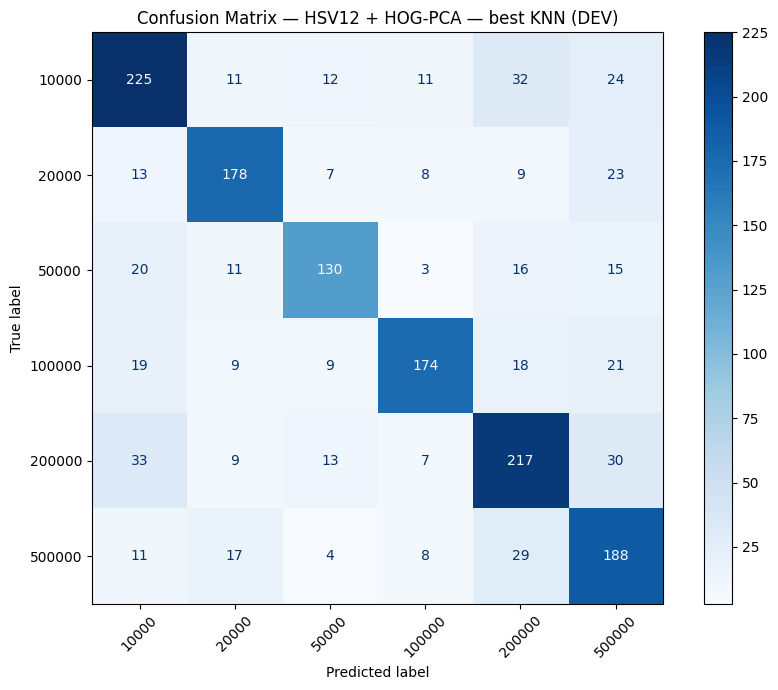

In [8]:
labels = np.sort(np.unique(y_train))
cm_fusion = confusion_matrix(y_dev, y_dev_pred_fusion, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_fusion, display_labels=labels)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title("Confusion Matrix — HSV12 + HOG-PCA — best KNN (DEV)")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix_dev.png", dpi=150)
plt.show()

In [9]:
# Precision / Recall / F1 theo mệnh giá — đọc được lớp nào mạnh/yếu
report_fusion = classification_report(
    y_dev, y_dev_pred_fusion,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_fusion = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_fusion[str(label)]["precision"],
        "recall": report_fusion[str(label)]["recall"],
        "f1": report_fusion[str(label)]["f1-score"],
        "support": int(report_fusion[str(label)]["support"]),
    }
    for label in labels
])
display(per_class_fusion)

print(f"Số ảnh đúng: {np.trace(cm_fusion)}/{cm_fusion.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.700935,0.714286,0.707547,315
1,20000,0.757447,0.747899,0.752643,238
2,50000,0.742857,0.666667,0.702703,195
3,100000,0.824645,0.696000,0.754881,250
4,200000,0.676012,0.702265,0.688889,309
5,500000,0.624585,0.731518,0.673835,257


Số ảnh đúng: 1112/1564


In [10]:
# Những cặp mệnh giá có tổng số nhầm lẫn hai chiều lớn nhất
error_pairs_fusion = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_fusion[i, j])
        errors_ji = int(cm_fusion[j, i])
        error_pairs_fusion.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_fusion = (
    pd.DataFrame(error_pairs_fusion)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:")
display(df_error_pairs_fusion.head(5))

Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,32,33,65
14,200000 ↔ 500000,30,29,59
8,20000 ↔ 500000,23,17,40
4,10000 ↔ 500000,24,11,35
1,10000 ↔ 50000,12,20,32


## 6. Lưu kết quả

Giữ dự đoán từng ảnh và bảng kết quả để so sánh với các nhánh riêng. Không chọn tham số bằng test. Chưa khóa cấu hình KNN cuối ở notebook này.

In [11]:
feature_name = "HSV12 + HOG-PCA"
summary_fusion = pd.DataFrame([{
    "feature": feature_name, "feature_dim": X_train_fusion.shape[1],
    "k": int(best_fusion["k"]), "weights": str(best_fusion["weights"]),
    "metric": str(best_fusion["metric"]),
    "macro_f1": fusion_scores["macro_f1"], "accuracy": fusion_scores["accuracy"],
    "mae_vnd": fusion_scores["mae_vnd"],
}])
df_results_fusion.to_csv(output_dir / "fusion_knn_grid_dev.csv", index=False)
summary_fusion.to_csv(output_dir / "fusion_best_dev.csv", index=False)
per_class_fusion.to_csv(output_dir / "per_class_dev.csv", index=False)
pd.DataFrame(cm_fusion, index=labels, columns=labels).to_csv(output_dir / "confusion_matrix_dev.csv")
df_error_pairs_fusion.to_csv(output_dir / "error_pairs_bidirectional_dev.csv", index=False)
predictions = dev_manifest[["relative_path"]].copy()
predictions["y_true_vnd"] = y_dev
predictions["y_pred_vnd"] = y_dev_pred_fusion
predictions.to_csv(output_dir / "predictions_dev.csv", index=False)
(output_dir / "metrics_dev.json").write_text(json.dumps(fusion_scores, indent=2), encoding="utf-8")

config = {
    "feature": feature_name, "image": "RGB uint8 224x224, OpenCV INTER_LINEAR",
    "hsv": "joint HSV12, OpenCV ranges, L2", "hog_source": HOG_DIR.name,
    "pca_on_hog": True, "branch_norm": "L2 separately", "concatenation_order": ["HSV12", "HOG branch"],
    "normalization_after_concat": False, "extra_branch_weights": False,
    "feature_dtype": "float32", "feature_dim": X_train_fusion.shape[1],
    "k_options": list(n_neighbors_options), "weight_options": weight_options,
    "metric_options": metric_options, "algorithm": "brute",
    "best_k": int(best_fusion["k"]), "best_weights": str(best_fusion["weights"]),
    "best_metric": str(best_fusion["metric"]),
}
(output_dir / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Đã lưu vào:", output_dir)
display(summary_fusion)

Đã lưu vào: C:\CS231\src\KNN\results_224\hsv12_hog_pca


,feature,feature_dim,k,weights,metric,macro_f1,accuracy,mae_vnd
0,HSV12 + HOG-PCA,3146,6,distance,euclidean,0.713416,0.710997,66086.956522


## 7. So sánh với các nhánh riêng

Bảng đầu so cấu hình tốt nhất mỗi phương án. Bảng sau giữ k=1, uniform, Euclidean để đối chiếu khi bộ phân loại cố định. Các nhánh thêm sau không mặc định phải tốt hơn; chưa chọn kết quả cuối toàn nhánh KNN.

In [12]:
hsv_best = pd.read_csv(RESULTS_ROOT / "hsv12" / "hsv12_best_dev.csv")
hog_best = pd.read_csv(HOG_DIR / (HOG_DIR.name + "_best_dev.csv"))
comparison = pd.concat([hsv_best, hog_best, summary_fusion], ignore_index=True)
comparison.to_csv(output_dir / "comparison_best_dev.csv", index=False)
display(comparison[["feature", "feature_dim", "k", "weights", "accuracy", "macro_f1", "mae_vnd"]])

hsv_grid = pd.read_csv(RESULTS_ROOT / "hsv12" / "hsv12_knn_grid_dev.csv")
hog_grid = pd.read_csv(HOG_DIR / (HOG_DIR.name + "_knn_grid_dev.csv"))
reference_rows = []
for name, grid in [("HSV12", hsv_grid), (HOG_DIR.name, hog_grid), (feature_name, df_results_fusion)]:
    row = grid.loc[(grid["k"] == 1) & (grid["weights"] == "uniform")].iloc[0].to_dict()
    row["feature"] = name
    reference_rows.append(row)
reference_comparison = pd.DataFrame(reference_rows)
reference_comparison.to_csv(output_dir / "comparison_reference_dev.csv", index=False)
display(reference_comparison[["feature", "k", "weights", "metric", "accuracy", "macro_f1", "mae_vnd"]])

,feature,feature_dim,k,weights,accuracy,macro_f1,mae_vnd
0,Histogram HSV 12x12x12,1728,1,uniform,0.796036,0.798307,46585.677749
1,HOG RGB224 + PCA95 + L2,1418,5,distance,0.443734,0.437934,106898.976982
2,HSV12 + HOG-PCA,3146,6,distance,0.710997,0.713416,66086.956522


,feature,k,weights,metric,accuracy,macro_f1,mae_vnd
0,HSV12,1,uniform,euclidean,0.796036,0.798307,46585.677749
1,hog_pca,1,uniform,euclidean,0.434783,0.431541,110249.360614
2,HSV12 + HOG-PCA,1,uniform,euclidean,0.699488,0.701336,66208.439898
